# Colombian politics

In [33]:
import numpy as np
import pandas as pd
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from networkx.algorithms.community import greedy_modularity_communities
from IPython.display import display

In [34]:

ARCHIVO_EXCEL = r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\python\others\data\raw_data_colombian_politics.xlsx"
HOJA = 1  # nombre o índice de hoja
# CARGAR DATOS
df = pd.read_excel(ARCHIVO_EXCEL, sheet_name=HOJA)
#df = df.drop_duplicates(subset=["NOMBRE"])
print("Dimensiones:", df.shape)


# COLUMNAS QUE REPRESENTAN CARGOS
columnas_excluir = ["NOMBRE", "EDAD", "GENERO",
    "PARTIDO_POLITICO", "NIVEL_DE_ESTUDIOS", "UNIVERSIDAD",
    "CARRERA", "PREDECESORES", "GOBERNACION",
    "FLAG_MINISTERIO", "FLAG_VIVO"]

columnas_cargos = []
for col in df.columns:
    if col in columnas_excluir:
        continue
    valores = set(df[col].dropna().unique())
    # Detectar columnas binarias
    if valores.issubset({0, 1}):
        columnas_cargos.append(col)
print("\nColumnas de cargos detectadas:")
print(columnas_cargos)

# CREAR GRAFO BIPARTITO
B = nx.Graph()

# AGREGAR NODOS DE PERSONAS
for _, row in df.iterrows():
    nombre = row["NOMBRE"]
    B.add_node(nombre, bipartite="persona", tipo="persona",
        edad=row.get("EDAD"),
        genero=row.get("GENERO"),
        partido=row.get("PARTIDO_POLITICO"),
        nivel_estudios=row.get("NIVEL_DE_ESTUDIOS"),
        universidad=row.get("UNIVERSIDAD"),
        carrera=row.get("CARRERA"),
        predecesores=row.get("PREDECESORES"),
        gobernacion=row.get("GOBERNACION"),
        flag_ministerio=row.get("FLAG_MINISTERIO"),
        flag_vivo=row.get("FLAG_VIVO"))

# AGREGAR NODOS DE CARGOS
for cargo in columnas_cargos:
    B.add_node(cargo, bipartite="cargo", tipo="cargo")

# AGREGAR ARISTAS PERSONA <-> CARGO
for _, row in df.iterrows():
    nombre = row["NOMBRE"]
    for cargo in columnas_cargos:
        if row[cargo] == 1:
            B.add_edge(nombre, cargo, relacion="ocupa")

print("\n================================")
print("GRAFO BIPARTITO CONSTRUIDO")
print("Nodos:", B.number_of_nodes())
print("Aristas:", B.number_of_edges())

# SEPARAR CONJUNTOS BIPARTITOS
personas = {n for n, d in B.nodes(data=True) if d["tipo"] == "persona"}
cargos = {n for n, d in B.nodes(data=True) if d["tipo"] == "cargo"}
print("\nNúmero de personas:", len(personas))
print("Número de cargos:", len(cargos))


# PROYECCIÓN PERSONA-PERSONA
from networkx.algorithms import bipartite
G_personas = bipartite.weighted_projected_graph(B, personas)
print("\n================================")
print("PROYECCIÓN PERSONA-PERSONA")
print("Nodos:", G_personas.number_of_nodes())
print("Aristas:", G_personas.number_of_edges())


Dimensiones: (265, 62)

Columnas de cargos detectadas:
['PRESIDENCIA', 'VICEPRESIDENCIA', 'SUBDIRECTOR_DAPRE', 'VIC_VIVIENDA', 'VIC_TRANSPORTE', 'VIC_SALUD', 'VIC_ENERGIA', 'VIC_JUSTICIA', 'VIC_INTERIOR', 'VIC_HACIENDA', 'VIC_EDUCACION', 'VIC_DEPORTE', 'VIC_DEFENSA', 'VIC_COMERCIO', 'VIC_AMBIENTE', 'VIC_TIC', 'VIC_TRABAJO', 'VIC_IGUALDAD', 'VIC_CULTURA', 'VIC_CIENCIAS', 'VIC_CANCILLERIA', 'VIC_AGRICULTURA', 'DAPRE_.DEPARTAMENTO_ADMINISTRATIVO_DE_LA_PRESIDENCIA.', 'AGRICULTURA', 'AMBIENTE', 'CANCILLERIA', 'CIENCIAS', 'COMERCIO', 'CULTURA', 'DEFENSA', 'DEPORTE', 'EDUCACION', 'HACIENDA', 'IGUALDAD', 'INTERIOR', 'JUSTICIA', 'ENERGIA', 'SALUD', 'TIC', 'TRABAJO', 'TRANSPORTE', 'VIVIENDA', 'DANE', 'DPN', 'PRESID_SENADO', 'PRESID_CAMARA_REPRESENTANTES', 'PROSPERIDAD_SOCIAL', 'DIAN', 'JEFE_DESPACHO_PRESIDENCIAL', 'SUPER_INTENDENCIA_INDUS_COMER']

GRAFO BIPARTITO CONSTRUIDO
Nodos: 314
Aristas: 379

Número de personas: 264
Número de cargos: 50

PROYECCIÓN PERSONA-PERSONA
Nodos: 264
Aristas: 2014


C:\Users\carlo\AppData\Local\Temp\ipykernel_16612\1147837169.py:290: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


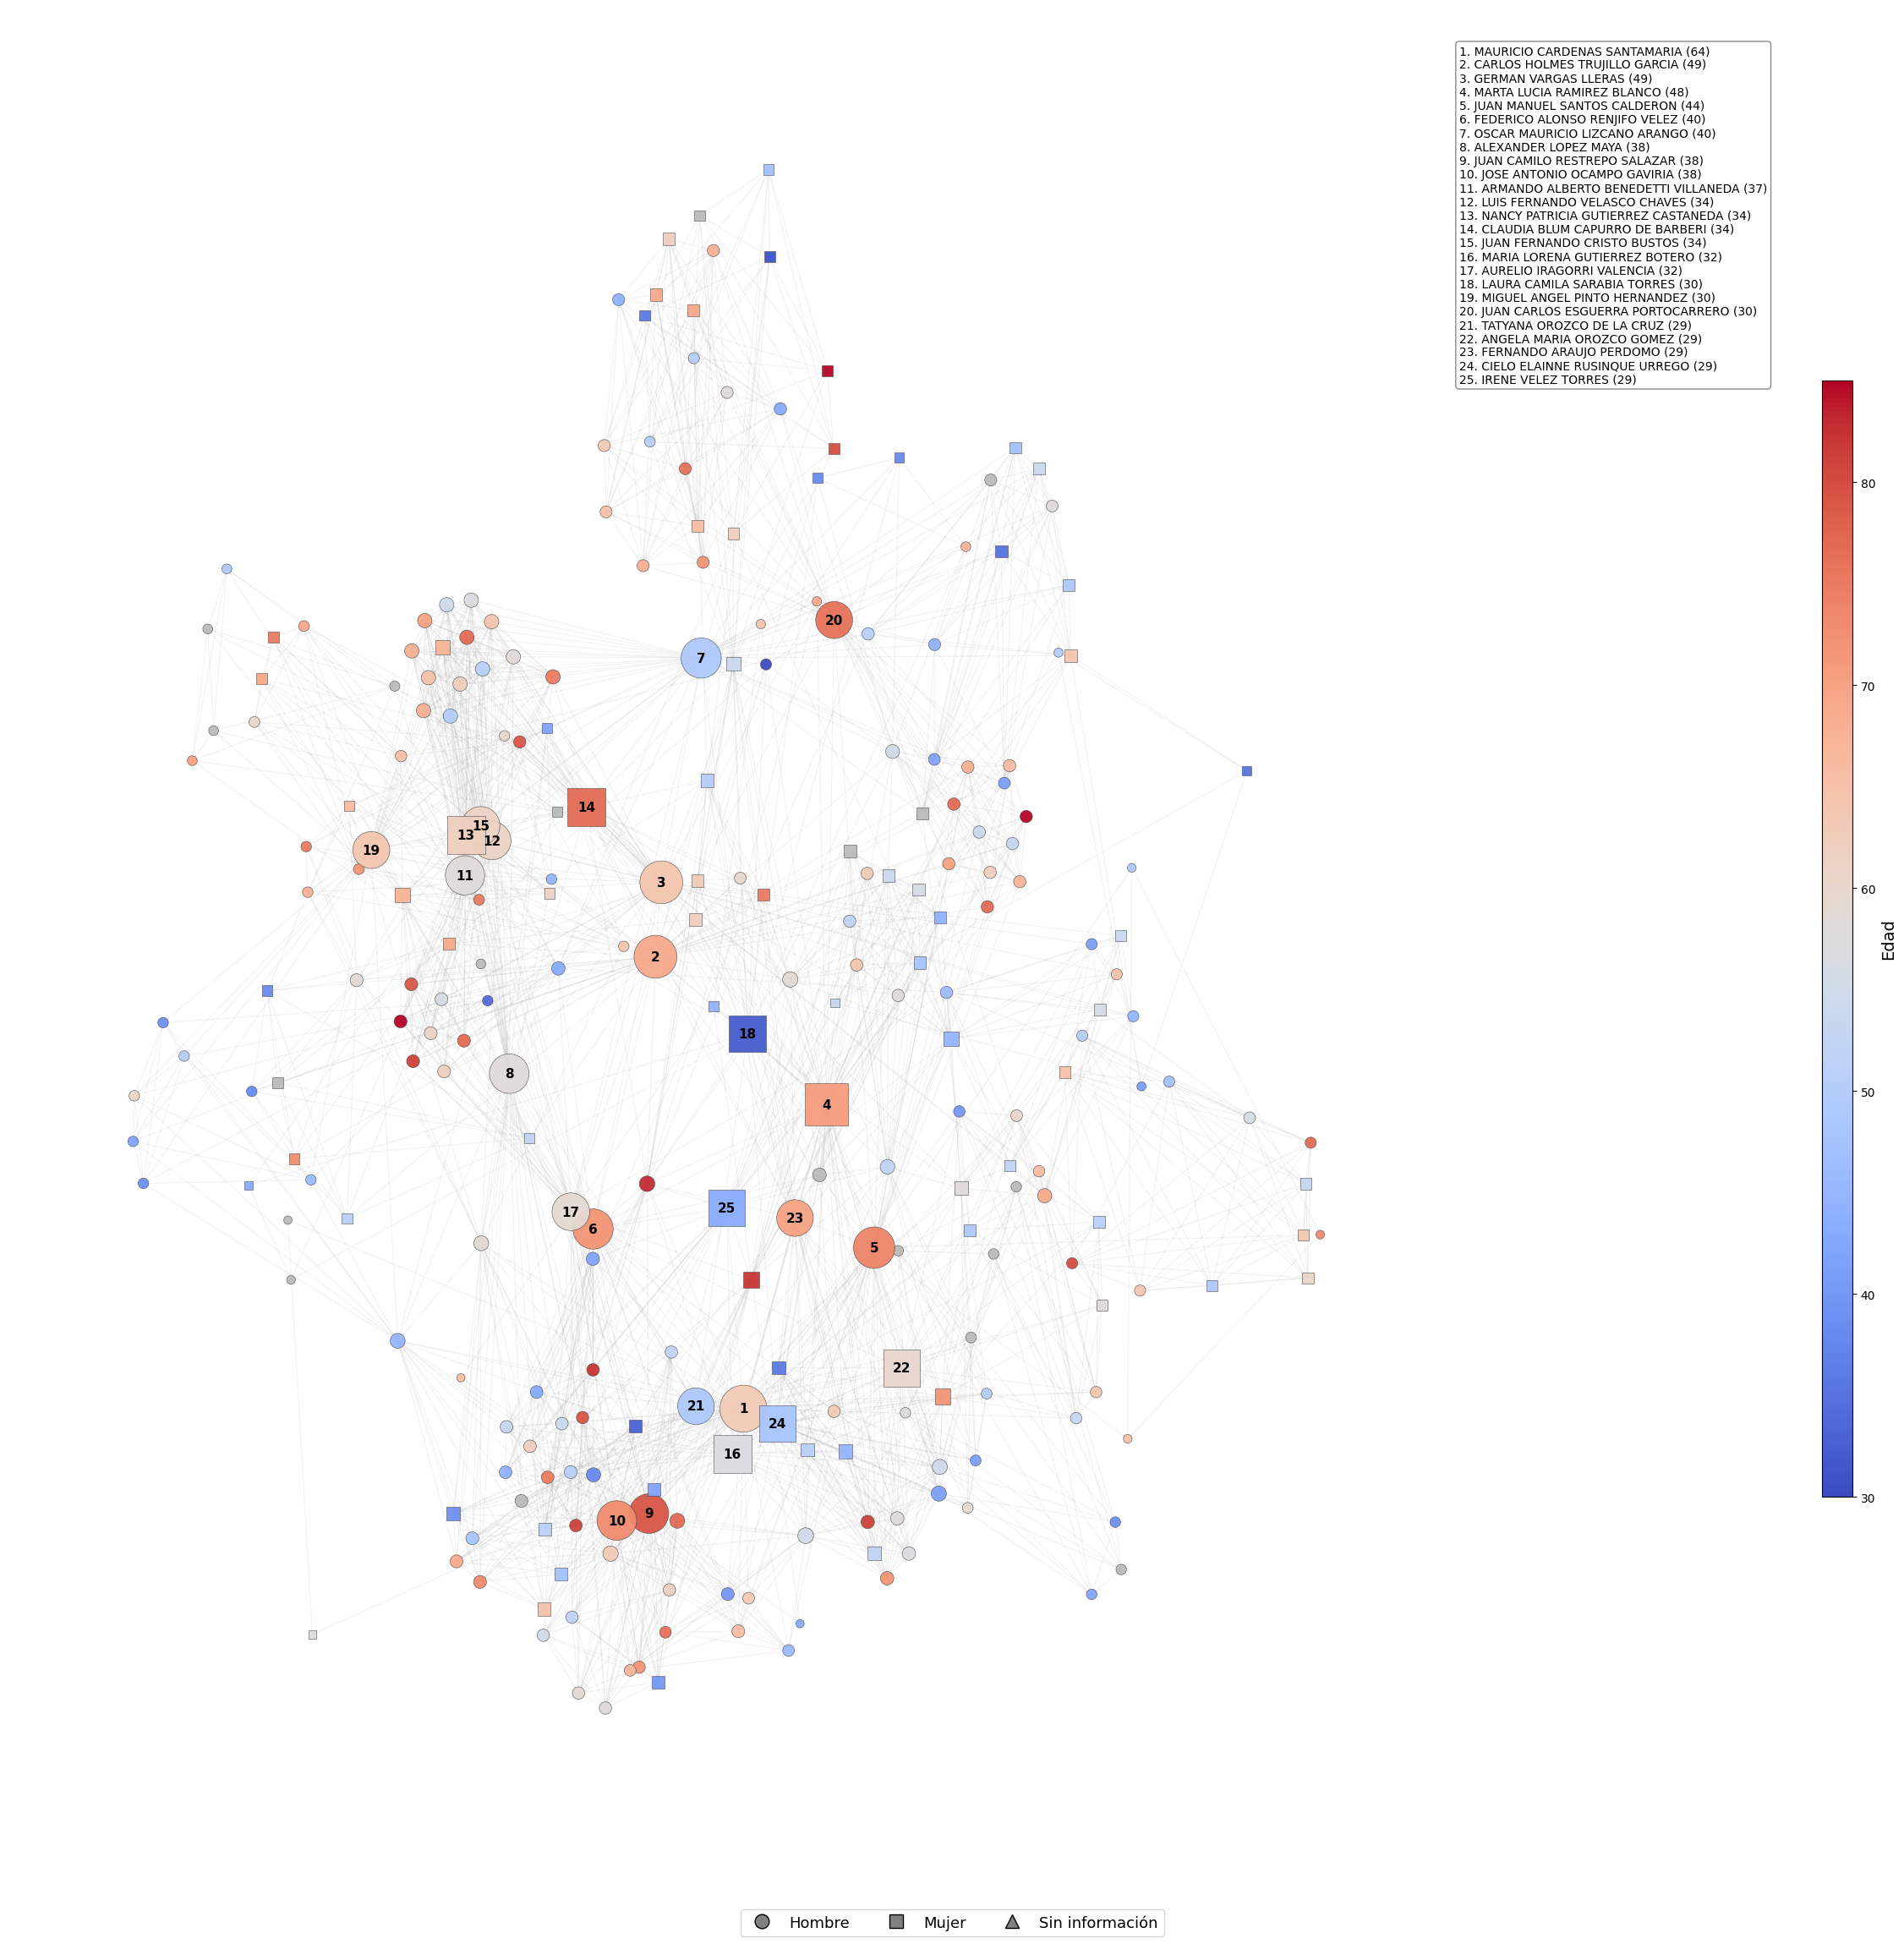

In [35]:

# VISUALIZACIÓN DE G_personas


genero_dict = dict(
    zip(df["NOMBRE"], df["GENERO"])
)

edad_dict = dict(
    zip(df["NOMBRE"], df["EDAD"])
)

gob_dict = dict(
    zip(df["NOMBRE"], df["GOBERNACION"])
)


grados = dict(G_personas.degree())


top_n = 25

top_nodes = sorted(
    grados.items(),
    key=lambda x: x[1],
    reverse=True
)[:top_n]

top_names = [x[0] for x in top_nodes]


edades_validas = [
    edad_dict[n]
    for n in G_personas.nodes()
    if pd.notna(edad_dict.get(n))
]

norm = mcolors.Normalize(
    vmin=min(edades_validas),
    vmax=max(edades_validas)
)

cmap = cm.coolwarm


pos = nx.spring_layout(
    G_personas,
    k=2.995,
    iterations=400,
    seed=42
)


fig, ax = plt.subplots(
    figsize=(24, 24)
)

#fig.patch.set_facecolor("#f4f4f4")
#ax.set_facecolor("#f4f4f4")


nx.draw_networkx_edges(
    G_personas,
    pos,
    ax=ax,
    alpha=0.10,
    width=0.8,
    edge_color="gray"
)


hombres = []
mujeres = []
otros = []

for n in G_personas.nodes():

    genero = str(
        genero_dict.get(n, "")
    ).upper()

    if genero.startswith("M"):

        hombres.append(n)

    elif genero.startswith("F"):

        mujeres.append(n)

    else:

        otros.append(n)


color_map = {}

for n in G_personas.nodes():

    edad = edad_dict.get(n)

    if pd.isna(edad):

        color_map[n] = "#BBBBBB"

    else:

        color_map[n] = cmap(norm(edad))


node_sizes = {}

for n in G_personas.nodes():

    g = grados[n]

    if n in top_names:

        node_sizes[n] = 450 + g * 18

    else:

        node_sizes[n] = 40 + g * 5


nx.draw_networkx_nodes(
    G_personas,
    pos,
    nodelist=hombres,
    node_shape='o',
    node_size=[
        node_sizes[n]
        for n in hombres
    ],
    node_color=[
        color_map[n]
        for n in hombres
    ],
    edgecolors="#444444",
    linewidths=0.4,
    alpha=0.95,
    ax=ax
)


nx.draw_networkx_nodes(
    G_personas,
    pos,
    nodelist=mujeres,
    node_shape='s',
    node_size=[
        node_sizes[n]
        for n in mujeres
    ],
    node_color=[
        color_map[n]
        for n in mujeres
    ],
    edgecolors="#444444",
    linewidths=0.4,
    alpha=0.95,
    ax=ax
)


nx.draw_networkx_nodes(
    G_personas,
    pos,
    nodelist=otros,
    node_shape='^',
    node_size=[
        node_sizes[n]
        for n in otros
    ],
    node_color=[
        color_map[n]
        for n in otros
    ],
    edgecolors="#444444",
    linewidths=0.4,
    alpha=0.95,
    ax=ax
)


labels = {}

leyenda_top = []

for idx, (node, grado) in enumerate(top_nodes, start=1):

    labels[node] = str(idx)

    leyenda_top.append(
        f"{idx}. {node} ({grado})"
    )

nx.draw_networkx_labels(
    G_personas,
    pos,
    labels=labels,
    font_size=11,
    font_weight="bold",
    font_color="black",
    ax=ax
)


texto_leyenda = "\n".join(leyenda_top)

ax.text(
    1.01,
    0.98,
    texto_leyenda,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="gray",
        alpha=0.92
    )
)


sm = cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar_ax = fig.add_axes(
    [0.90, 0.22, 0.015, 0.55]
)

cbar = fig.colorbar(
    sm,
    cax=cbar_ax
)

cbar.set_label(
    "Edad",
    fontsize=14
)


legend_elements = [

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='Hombre',
        markerfacecolor='gray',
        markeredgecolor='black',
        markersize=12
    ),

    Line2D(
        [0], [0],
        marker='s',
        color='w',
        label='Mujer',
        markerfacecolor='gray',
        markeredgecolor='black',
        markersize=12
    ),

    Line2D(
        [0], [0],
        marker='^',
        color='w',
        label='Sin información',
        markerfacecolor='gray',
        markeredgecolor='black',
        markersize=12
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    fontsize=13
)


ax.axis("off")

plt.tight_layout(
    rect=[0, 0.03, 0.88, 0.96]
)

plt.show()

In [36]:
import networkx as nx
import numpy as np
import pandas as pd
import pickle
import time

from tqdm.auto import tqdm
import blockdynamicnetworks as bdn

In [37]:
G_real = nx.Graph()

# Conservar nodos y atributos
G_real.add_nodes_from(G_personas.nodes(data=True))

# Agregar únicamente relaciones binarias
for u, v, data in G_personas.edges(data=True):

    # Eliminar autoenlaces
    if u == v:
        continue

    # Agregar relación binaria
    G_real.add_edge(u, v, weight=1)


# Verificar propiedades
print("RED POLÍTICA COLOMBIANA")
print("=" * 40)

print("Nodos:", G_real.number_of_nodes())
print("Aristas:", G_real.number_of_edges())
print("Dirigida:", G_real.is_directed())
print("Autoenlaces:", nx.number_of_selfloops(G_real))
print("Densidad:", nx.density(G_real))

RED POLÍTICA COLOMBIANA
Nodos: 264
Aristas: 2014
Dirigida: False
Autoenlaces: 0
Densidad: 0.05801359603640972


In [38]:

import community as community_louvain  # python-louvain

partition_louvain = community_louvain.best_partition(
    G_real,
    weight="weight",
    random_state=123
)

labels_louvain = [
    partition_louvain[node]
    for node in G_real.nodes()
]

z0 = bdn.Partition(labels_louvain)

print("\nParticion inicial - Louvain")

print("Número de nodos:", z0.size())
print("Número de comunidades:", z0.number_of_communities())
print("Tamaños de comunidades:", z0.community_sizes())
print("Etiquetas:", z0.labels())


Particion inicial - Louvain
Número de nodos: 264
Número de comunidades: 13
Tamaños de comunidades: [11, 60, 16, 28, 31, 25, 15, 25, 10, 14, 7, 7, 15]
Etiquetas: [0, 1, 2, 3, 4, 2, 1, 1, 5, 4, 6, 7, 8, 5, 7, 1, 9, 2, 1, 4, 10, 9, 4, 7, 4, 11, 7, 1, 7, 11, 1, 4, 12, 6, 1, 1, 8, 3, 12, 6, 6, 1, 1, 2, 9, 5, 1, 1, 1, 4, 2, 6, 3, 4, 1, 0, 12, 0, 3, 2, 8, 4, 6, 5, 4, 1, 3, 1, 3, 0, 9, 3, 1, 1, 1, 12, 2, 7, 1, 1, 8, 4, 10, 1, 8, 5, 12, 1, 2, 4, 7, 5, 11, 5, 9, 10, 5, 5, 12, 9, 6, 1, 3, 4, 7, 3, 1, 4, 2, 3, 8, 7, 1, 4, 0, 8, 10, 6, 12, 1, 8, 1, 1, 3, 2, 3, 4, 10, 1, 7, 4, 4, 7, 1, 6, 6, 6, 10, 1, 7, 9, 11, 0, 1, 1, 7, 0, 4, 7, 3, 7, 12, 5, 1, 1, 1, 12, 4, 5, 9, 4, 3, 5, 5, 4, 12, 4, 1, 7, 7, 3, 6, 7, 0, 1, 3, 3, 1, 11, 2, 12, 1, 1, 3, 1, 2, 11, 5, 5, 5, 7, 1, 5, 3, 4, 1, 1, 5, 3, 6, 7, 4, 5, 1, 1, 9, 8, 5, 1, 5, 3, 1, 8, 4, 5, 1, 12, 4, 5, 2, 12, 5, 7, 9, 1, 7, 4, 9, 1, 3, 6, 0, 1, 12, 4, 7, 9, 12, 11, 4, 4, 3, 3, 1, 1, 2, 3, 1, 2, 2, 10, 9, 7, 3, 3, 7, 3, 9, 6, 0, 0, 1, 1, 5]


In [39]:
# ============================================================
# 2. CONVERTIR NETWORKX A BLOCKDYNAMICNETWORKS
# ============================================================

def networkx_to_bdn(G_nx):

    nodes = list(G_nx.nodes())

    node_to_index = {
        node: i for i, node in enumerate(nodes)
    }

    G_bdn = bdn.Graph(len(nodes))

    for u, v in G_nx.edges():

        i = node_to_index[u]
        j = node_to_index[v]

        # Evitar autoenlaces
        if i != j:
            G_bdn.add_edge(i, j)

    return G_bdn, nodes, node_to_index

G_bdn, nodes, node_to_index = networkx_to_bdn(G_real)

print("\nRED BDN")
print("=" * 40)

print("Nodos:", G_bdn.size())
print("Aristas:", G_bdn.number_of_edges())

adjacency = nx.to_numpy_array(
    G_real,
    nodelist=nodes,
    dtype=int,
    weight=None
)


RED BDN
Nodos: 264
Aristas: 2014


In [16]:
import numpy as np
from scipy.optimize import brentq
from scipy.special import gammaln
from scipy.stats import poisson

# ============================================================
# FUNCIONES AUXILIARES
# ============================================================

def rising_log(a, n):
    """Logaritmo del factorial ascendente (a)_n."""
    return gammaln(a + n) - gammaln(a)


# ============================================================
# 1. DP
# ============================================================

def expected_K_DP(n, alpha):
    i = np.arange(n)
    return np.sum(alpha / (alpha + i))


def calibrate_DP(n, K_target):
    return brentq(
        lambda alpha: expected_K_DP(n, alpha) - K_target,
        1e-8,
        1e6
    )


# ============================================================
# 2. PY
# ============================================================

def expected_K_PY(n, alpha, sigma):
    i = np.arange(n)
    return np.sum((alpha + sigma * i) / (alpha + i))


def calibrate_PY(n, K_target, sigma=0.1):

    if not (0 <= sigma < 1):
        raise ValueError("sigma debe estar entre 0 y 1.")

    lower = -sigma + 1e-8

    K_min = expected_K_PY(n, lower, sigma)
    K_max = expected_K_PY(n, 1e6, sigma)

    if not (K_min <= K_target <= K_max):
        raise ValueError(
            f"Objetivo no alcanzable para PY con sigma={sigma}. "
            f"El rango aproximado de E[K] es "
            f"[{K_min:.4f}, {K_max:.4f}]."
        )

    return brentq(
        lambda alpha: expected_K_PY(n, alpha, sigma) - K_target,
        lower,
        1e6
    )


# ============================================================
# 3. DM
# ============================================================

def expected_K_DM(n, beta, H):

    log_p_empty = (
        rising_log((H - 1) * beta, n)
        - rising_log(H * beta, n)
    )

    return H * (1 - np.exp(log_p_empty))


def calibrate_DM(n, K_target, H):

    if K_target > H:
        raise ValueError("K_target no puede superar H.")

    return brentq(
        lambda beta: expected_K_DM(n, beta, H) - K_target,
        1e-8,
        1e5
    )


# ============================================================
# 4. MFM
# ============================================================

def expected_K_MFM(n, rho, p_k):
    """
    p_k[m-1] = P(M=m)
    rho = parámetro Dirichlet por componente
    """

    p_k = np.asarray(p_k, dtype=float)
    p_k = p_k / p_k.sum()

    M_values = np.arange(1, len(p_k) + 1)
    expected = 0.0

    for M, pM in zip(M_values, p_k):

        if pM == 0:
            continue

        log_p_empty = (
            rising_log((M - 1) * rho, n)
            - rising_log(M * rho, n)
        )

        expected_conditional = M * (1 - np.exp(log_p_empty))
        expected += pM * expected_conditional

    return expected


def calibrate_MFM(n, K_target, p_k):

    max_K = len(p_k)

    if K_target > max_K:
        raise ValueError(
            "K_target supera el máximo número de componentes M."
        )

    return brentq(
        lambda rho: expected_K_MFM(n, rho, p_k) - K_target,
        1e-8,
        1e5
    )


# ============================================================
# 5. PCPP
# ============================================================

def expected_K_PCPP(n, theta, omega, tol=1e-10):
    """
    M = 1 + Poisson(theta).

    Usa la aproximación de Dirichlet que aparece en tu
    implementación C++ cuando omega > 0.
    """

    # Truncamiento de la distribución de M
    M_max = int(poisson.ppf(1 - tol, theta)) + 1
    M_values = np.arange(1, M_max + 1)

    probabilities = poisson.pmf(M_values - 1, theta)
    probabilities /= probabilities.sum()

    expected = 0.0

    for M, pM in zip(M_values, probabilities):

        if M == 1:
            expected_conditional = 1.0
            expected += pM * expected_conditional
            continue

        if omega == 0:

            log_p_empty = n * np.log((M - 1) / M)

        else:

            alpha_M = M / (omega**2) - 1 / M

            log_p_empty = (
                rising_log((M - 1) * alpha_M, n)
                - rising_log(M * alpha_M, n)
            )

        expected_conditional = M * (1 - np.exp(log_p_empty))
        expected += pM * expected_conditional

    return expected


def calibrate_PCPP(n, K_target, omega=0.0, tol=1e-10):

    def objective(theta):
        return expected_K_PCPP(n, theta, omega, tol) - K_target

    return brentq(objective, 1e-8, 1e4)


# ============================================================
# 6. GN: CALIBRACIÓN POR SIMULACIÓN
# ============================================================

def simulate_GN_partition(n, gamma, seed=None):

    rng = np.random.default_rng(seed)

    prior = bdn.PartitionPrior(
        bdn.PriorType.GN,
        gamma
    )

    labels = [0]

    for i in range(1, n):

        current = bdn.Partition(labels)
        K = len(set(labels))

        candidates = []

        # Asignar a cada comunidad existente
        for k in range(K):
            new_labels = labels.copy()

            old_label = sorted(set(labels))[k]
            new_labels.append(old_label)

            candidates.append(new_labels)

        # Crear nueva comunidad
        new_labels = labels.copy()
        new_labels.append(max(labels) + 1)
        candidates.append(new_labels)

        # Calcular probabilidades predictivas mediante
        # las probabilidades de las particiones candidatas
        log_probs = np.array([
            prior.log_probability(bdn.Partition(candidate))
            for candidate in candidates
        ])

        log_probs -= np.max(log_probs)
        probs = np.exp(log_probs)
        probs /= probs.sum()

        chosen = rng.choice(len(candidates), p=probs)
        labels = candidates[chosen]

    return len(set(labels))


def expected_K_GN_MC(n, gamma, simulations=200, seed=123):

    values = [
        simulate_GN_partition(
            n,
            gamma,
            seed=seed + s
        )
        for s in range(simulations)
    ]

    return np.mean(values)


def calibrate_GN_MC(n, K_target, simulations=200, seed=123):

    # Búsqueda sobre una grilla porque la estimación Monte Carlo
    # no es completamente suave.

    gamma_grid = np.linspace(0.5, 0.6, 11)

    results = []

    for gamma in gamma_grid:

        K_est = expected_K_GN_MC(
            n,
            gamma,
            simulations=simulations,
            seed=seed
        )

        results.append((gamma, K_est))

    best_gamma, best_K = min(
        results,
        key=lambda x: abs(x[1] - K_target)
    )

    return best_gamma, best_K, results

# ============================================================
# CONFIGURACIÓN
# ============================================================

K_target = 10
n = 264

# ---------------- DP ----------------
alpha_DP = calibrate_DP(n, K_target)

# ---------------- PY ----------------
sigma_PY = 0.01

alpha_PY = calibrate_PY(
    n,
    K_target,
    sigma=sigma_PY
)

# ---------------- DM ----------------
H_DM = 30

beta_DM = calibrate_DM(
    n,
    K_target,
    H=H_DM
)

# ---------------- MFM ----------------
# Distribución de M: P(M=m)
# Ejemplo: distribución uniforme sobre M=1,...,30

p_k_MFM = np.ones(30) / 30

rho_MFM = calibrate_MFM(
    n,
    K_target,
    p_k=p_k_MFM
)

# ---------------- GN ----------------
gamma_GN, K_GN_est, GN_results = calibrate_GN_MC(
    n,
    K_target,
    simulations=100
)

# ---------------- PCPP ----------------
omega_PCPP = 0.5

theta_PCPP = K_target -1 

# ============================================================
# RESULTADOS
# ============================================================

print("Objetivo E[K] =", K_target)

print("\nDP")
print("alpha =", alpha_DP)
print("E[K] =", expected_K_DP(n, alpha_DP))

print("\nPY")
print("alpha =", alpha_PY)
print("sigma =", sigma_PY)
print("E[K] =", expected_K_PY(n, alpha_PY, sigma_PY))

print("\nDM")
print("beta =", beta_DM)
print("H =", H_DM)
print("E[K] =", expected_K_DM(n, beta_DM, H_DM))

print("\nMFM")
print("rho =", rho_MFM)
print("E[K] =", expected_K_MFM(n, rho_MFM, p_k_MFM))

print("\nGN")
print("gamma =", gamma_GN)
print("E[K] estimado por simulación =", K_GN_est)

print("\nPCPP")
print("theta =", theta_PCPP)
print("omega =", omega_PCPP)
print("E[K] =", expected_K_PCPP(
    n, theta_PCPP, omega_PCPP
))

Objetivo E[K] = 10

DP
alpha = 1.918466168283546
E[K] = 10.000000000000517

PY
alpha = 1.291061303823689
sigma = 0.01
E[K] = 10.0

DM
beta = 0.08253466813107523
H = 30
E[K] = 9.999999999984

MFM
rho = 0.24597707294209856
E[K] = 10.000000000000098

GN
gamma = 0.6
E[K] estimado por simulación = 13.56

PCPP
theta = 9
omega = 0.5
E[K] = 9.999999116598932


In [14]:


# ============================================================
# CONFIGURACIÓN GENERAL
# ============================================================

n = 264
K_target = 10


# ============================================================
# 1. DP — Dirichlet Process
# ============================================================

alpha_DP = 1.918466168283546


# ============================================================
# 2. PY — Pitman-Yor
# ============================================================

alpha_PY = 1.291061303823689
sigma_PY = 0.01


# ============================================================
# 3. DM — Dirichlet Multinomial
# ============================================================

beta_DM = 0.08253466813107523
H_DM = 30


# ============================================================
# 4. MFM — Mixture of Finite Mixtures
# ============================================================

rho_MFM = 0.24597707294209856
p_k_MFM = np.ones(30) / 30


# ============================================================
# 5. GN — Gibbs-type prior (calibración Monte Carlo)
# ============================================================

gamma_GN = 0.6
K_GN_est = 13.56  

# ============================================================
# 6. PCPP
# ============================================================

omega_PCPP = 0.5
theta_PCPP = 9


In [4]:
# ============================================================
# 3. CONFIGURAR LAS SEIS PRIORS
# ============================================================

# DP
prior_DP = bdn.PartitionPrior(
    alpha=alpha_DP
)

# PY
prior_PY = bdn.PartitionPrior(
    type=bdn.PriorType.PY,
    alpha=alpha_PY,
    sigma=sigma_PY
)

# DM
prior_DM = bdn.PartitionPrior(
    type=bdn.PriorType.DM,
    beta=beta_DM,
    H_total=int(H_DM)
)

# GN
prior_GN = bdn.PartitionPrior(
    type=bdn.PriorType.GN,
    gamma=gamma_GN
)

# MFM
prior_MFM = bdn.PartitionPrior(
    type=bdn.PriorType.MFM,
    rho=rho_MFM,
    p_k=p_k_MFM
)

# PCPP
prior_PCPP = bdn.PartitionPrior(
    type=bdn.PriorType.PCPP,
    theta=theta_PCPP,
    omega=omega_PCPP,
    pcpp_tol=0.01
)


# ============================================================
# 4. AGRUPAR PRIORS Y PARÁMETROS
# ============================================================

priors = {

    "DP": {
        "prior": prior_DP,
        "parameters": {"alpha": alpha_DP}
    },

    "PY": {
        "prior": prior_PY,
        "parameters": {
            "alpha": alpha_PY,
            "sigma": sigma_PY
        }
    },

    "DM": {
        "prior": prior_DM,
        "parameters": {
            "beta": beta_DM,
            "H": H_DM
        }
    },

    "GN": {
        "prior": prior_GN,
        "parameters": {"gamma": gamma_GN}
    },

    "MFM": {
        "prior": prior_MFM,
        "parameters": {
            "rho": rho_MFM,
            "p_k": p_k_MFM
        }
    },

    "PCPP": {
        "prior": prior_PCPP,
        "parameters": {
            "theta": theta_PCPP,
            "omega": omega_PCPP,
            "pcpp_tol": 0.01
        }
    }
}

In [17]:
# ============================================================
# 5. PARÁMETROS DE LA INFERENCIA
# ============================================================

ITERATIONS = 11_000

BURN_IN = 1_000

THINNING = 10

SEED = 123

A = 1.0
B = 1.0

SBM SIMULADO
Número de nodos: 99
Número de aristas: 1170
Comunidades reales: 3
Tamaños reales: [33, 33, 33]

INFERENCIA
Número de muestras: 5000
Iteraciones Gibbs: 6401
Iteraciones Split-Merge: 19099

DIAGNÓSTICOS
ESS K: 1196.5236761435133
ESS log-posterior: 533.4437918300745
Tasa aceptación Split: 0.0013407072230601643
Tasa aceptación Merge: 0.0007614986293024672

Partición final:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Split attempts: 5967
Split accepted: 8
Merge attempts: 13132
Merge accepted: 10
Split acceptance rate: 0.0013407072230601643
Merge acceptance rate: 0.0007614986293024672
Comunidades finales: 3
Tamaños: {np.int64(0): np.int64(33), np.int64(1): np.int64(33), np.int64(2): np.int64(33)}
Adjusted Rand Index (ARI): 1.0


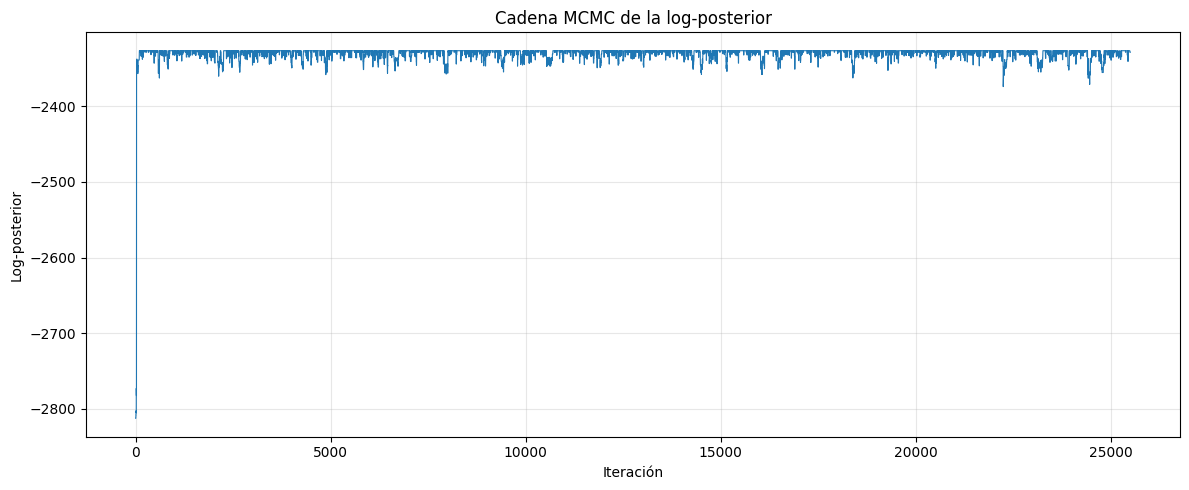

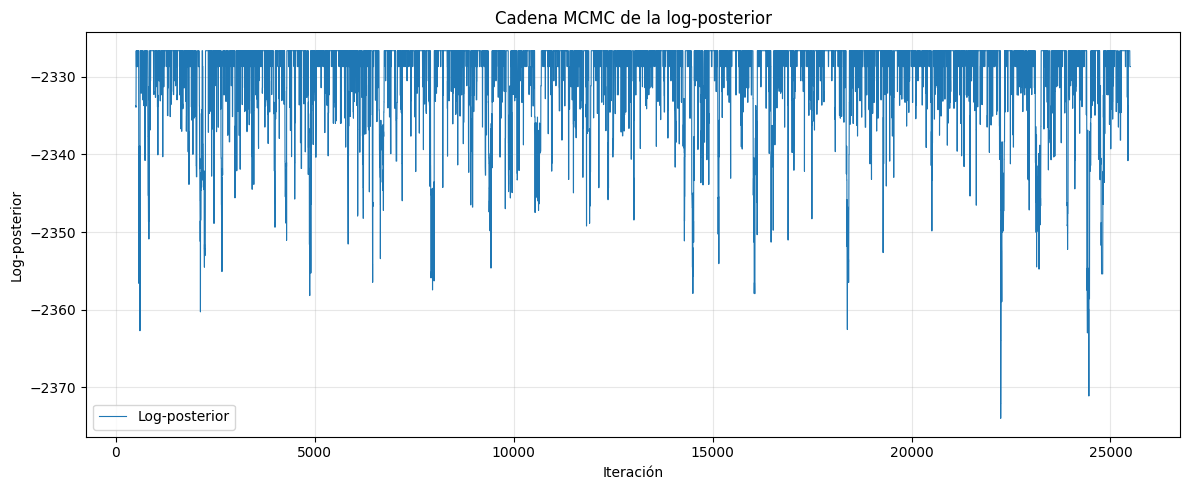

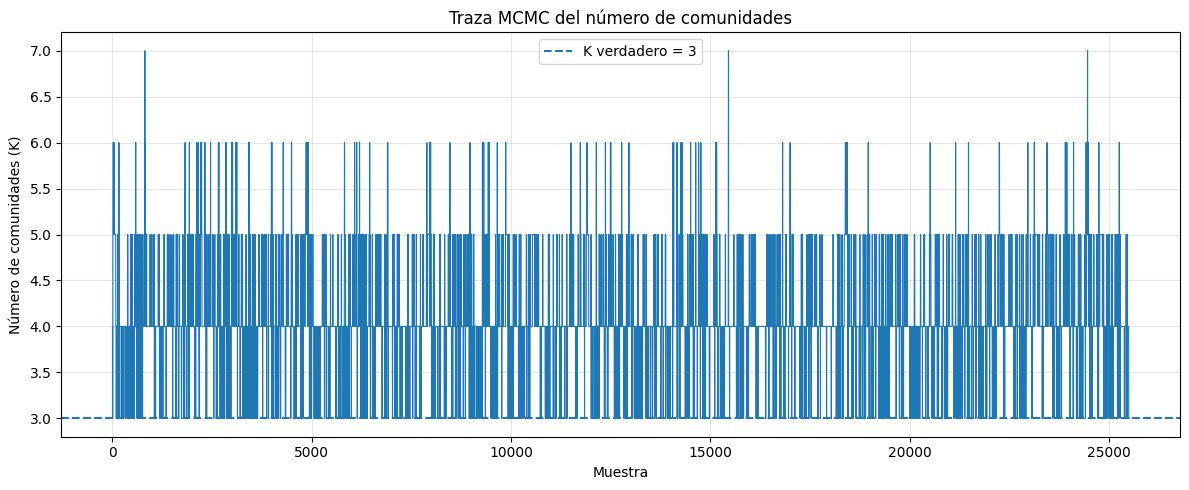

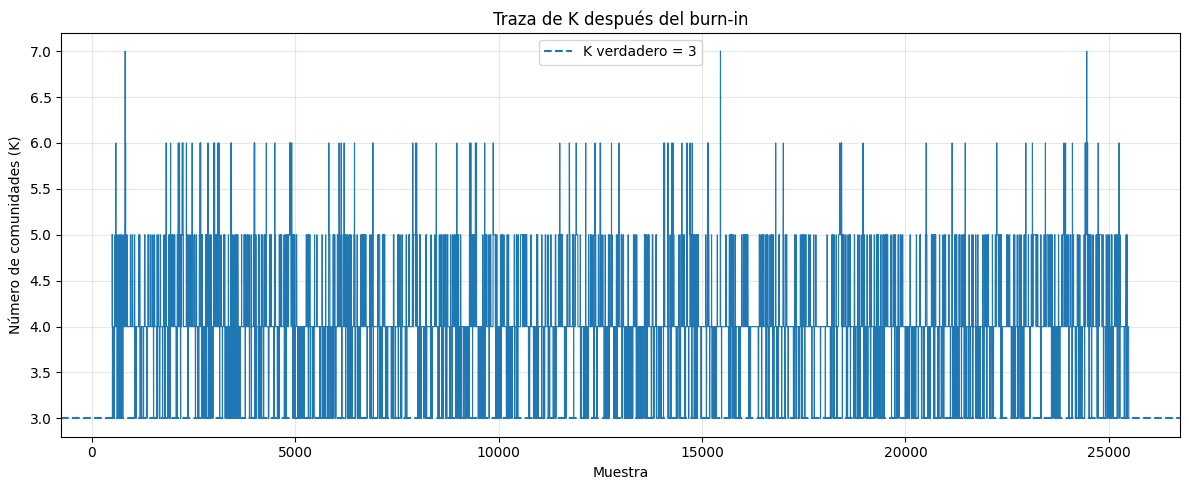

In [1]:
import numpy as np
import networkx as nx
import blockdynamicnetworks as bdn

# ============================================================
# 1. CONFIGURACIÓN DEL SBM
# ============================================================

n = 99                 # Número de nodos (elegido por el usuario)
K_true = 3              # Número real de comunidades
p_in = 0.50             # Probabilidad de conexión dentro de comunidad
p_out = 0.10            # Probabilidad de conexión entre comunidades

ITERATIONS = 25500
BURN_IN = 500
THINNING = 5
SEED = 123


# ============================================================
# 2. GENERAR LA ESTRUCTURA COMUNITARIA
# ============================================================

# Distribuir los n nodos entre las K comunidades
sizes = [n // K_true] * K_true

# Distribuir los nodos restantes
for i in range(n % K_true):
    sizes[i] += 1

# Matriz de probabilidades de conexión
probability_matrix = np.full(
    (K_true, K_true),
    p_out
)

np.fill_diagonal(
    probability_matrix,
    p_in
)

# Generar el SBM
G_real = nx.stochastic_block_model(
    sizes,
    probability_matrix,
    seed=SEED
)

# Etiquetas verdaderas de comunidad
z_true = np.array(G_real.graph["partition"])


# ============================================================
# 3. CONVERTIR NETWORKX A BLOCKDYNAMICNETWORKS
# ============================================================

nodes = list(G_real.nodes())

node_to_index = {
    node: i for i, node in enumerate(nodes)
}

graph = bdn.Graph(n)

for u, v in G_real.edges():

    i = node_to_index[u]
    j = node_to_index[v]

    if i != j:
        graph.add_edge(i, j)


# ============================================================
# 4. PARTICIÓN INICIAL
# ============================================================

# Crear una partición aleatoria inicial de K_true comunidades
rng = np.random.default_rng(SEED)

z0 = rng.integers(
    0,
    K_true,
    size=n
)

partition = bdn.Partition(z0.tolist())


# ============================================================
# 5. CREAR EL PRIOR
# ============================================================

prior = bdn.PartitionPrior(1.0)


# ============================================================
# 6. CREAR EL MODELO POSTERIOR
# ============================================================

posterior = bdn.PosteriorModel(
    graph,
    prior
)


# ============================================================
# 7. CREAR HYBRID SAMPLER
# ============================================================

sampler = bdn.HybridSampler(
    posterior,
    iterations=ITERATIONS,
    burn_in=BURN_IN,
    thinning=THINNING,
    seed=SEED,
    gibbs_probability=0.25
)


# ============================================================
# 8. EJECUTAR
# ============================================================

sampler.run(partition)


# ============================================================
# 9. CONSULTAR RESULTADOS
# ============================================================

results = sampler.results()

print("=" * 50)
print("SBM SIMULADO")
print("=" * 50)

print("Número de nodos:", graph.size())
print("Número de aristas:", graph.number_of_edges())
print("Comunidades reales:", K_true)
print("Tamaños reales:", sizes)

print("\nINFERENCIA")

print("Número de muestras:", len(sampler.samples()))
print("Iteraciones Gibbs:", sampler.gibbs_iterations())
print("Iteraciones Split-Merge:", sampler.split_merge_iterations())

print("\nDIAGNÓSTICOS")

print("ESS K:", results.ess_k)
print("ESS log-posterior:", results.ess_log_posterior)

print("Tasa aceptación Split:",
      results.split_acceptance_rate)

print("Tasa aceptación Merge:",
      results.merge_acceptance_rate)

print("\nPartición final:")
print(sampler.final_partition().labels())

results = sampler.results()

print("Split attempts:", np.sum(results.split_attempt_trace))
print("Split accepted:", np.sum(results.split_acceptance_trace))

print("Merge attempts:", np.sum(results.merge_attempt_trace))
print("Merge accepted:", np.sum(results.merge_acceptance_trace))

print("Split acceptance rate:", results.split_acceptance_rate)
print("Merge acceptance rate:", results.merge_acceptance_rate)

z_final = np.array(sampler.final_partition().labels())

unique, counts = np.unique(z_final, return_counts=True)

print("Comunidades finales:", len(unique))
print("Tamaños:", dict(zip(unique, counts)))

from sklearn.metrics import adjusted_rand_score
import numpy as np

z_true = np.repeat(np.arange(K_true), sizes)

z_estimated = np.array(
    sampler.final_partition().labels()
)

ari = adjusted_rand_score(z_true, z_estimated)

print("Adjusted Rand Index (ARI):", ari)



import numpy as np
import matplotlib.pyplot as plt

# Obtener resultados
results = sampler.results()

log_posterior = np.array(results.log_posterior_trace)

# Eje de iteraciones
iterations = np.arange(len(log_posterior))

# ============================================================
# VISUALIZACIÓN DE LA CADENA DE LOG-POSTERIOR
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    iterations,
    log_posterior,
    linewidth=0.8
)

plt.xlabel("Iteración")
plt.ylabel("Log-posterior")
plt.title("Cadena MCMC de la log-posterior")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))

plt.plot(
    iterations[BURN_IN:],
    log_posterior[BURN_IN:],
    linewidth=0.8,
    label="Log-posterior"
)


plt.xlabel("Iteración")
plt.ylabel("Log-posterior")
plt.title("Cadena MCMC de la log-posterior")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()





import numpy as np
import matplotlib.pyplot as plt

results = sampler.results()

k_trace = np.array(results.k_trace)
iterations = np.arange(len(k_trace))

plt.figure(figsize=(12, 5))

plt.plot(
    iterations,
    k_trace,
    linewidth=0.8
)

plt.axhline(
    K_true,
    linestyle="--",
    label=f"K verdadero = {K_true}"
)

plt.xlabel("Muestra")
plt.ylabel("Número de comunidades (K)")
plt.title("Traza MCMC del número de comunidades")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()




k_post = k_trace[BURN_IN:]

iterations_post = np.arange(
    BURN_IN,
    len(k_trace)
)

plt.figure(figsize=(12, 5))

plt.plot(
    iterations_post,
    k_post,
    linewidth=0.8
)

plt.axhline(
    K_true,
    linestyle="--",
    label=f"K verdadero = {K_true}"
)

plt.xlabel("Muestra")
plt.ylabel("Número de comunidades (K)")
plt.title("Traza de K después del burn-in")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# 6. EJECUTAR LAS SEIS INFERENCIAS

all_results = {}

total_runs = len(priors)


# ------------------------------------------------------------
# Información de la red
# ------------------------------------------------------------

n = G_bdn.size()
m = G_bdn.number_of_edges()

adjacency = nx.to_numpy_array(
    G_real,
    nodelist=nodes,
    dtype=int,
    weight=None
)

node_attributes = {
    node: G_real.nodes[node].copy()
    for node in nodes
}

degree = np.array([
    G_real.degree(node)
    for node in nodes
])


# ------------------------------------------------------------
# Ejecutar cada prior
# ------------------------------------------------------------

for prior_name, prior_info in tqdm(
    priors.items(),
    total=len(priors),
    desc="Inferencias SBM"
):

    prior = prior_info["prior"]
    prior_parameters = prior_info["parameters"]

    print(f"\nIniciando prior: {prior_name}", flush=True)

    run_name = f"politica_colombiana_{prior_name}"

    start_time = time.time()

    try:

        # 1. Modelo posterior
        model = bdn.PosteriorModel(
            G_bdn,
            prior,
            A,
            B
        )


        # 2. Sampler Hybrid
        sampler = bdn.HybridSampler(
            model,
            iterations=ITERATIONS,
            burn_in=BURN_IN,
            thinning=THINNING,
            seed=SEED,
            gibbs_probability=0.25
        )


        # 3. Ejecutar inferencia
        sampler.run(z0)


        # 4. Obtener resultados
        samples = sampler.samples()

        k_trace = sampler.number_of_communities()

        z_final = sampler.final_partition()

        results = sampler.results()


        # Trazas
        log_posterior_trace = np.array(
            results.log_posterior_trace
        )

        sampler_selection_trace = np.array(
            results.sampler_selection_trace
        )


        # 5. Etiquetas de las particiones guardadas
        sample_labels = np.array([
            s.labels() for s in samples
        ])


        # 6. Tiempo de ejecución
        elapsed = time.time() - start_time


        # ----------------------------------------------------
        # GUARDAR RESULTADOS
        # ----------------------------------------------------

        all_results[run_name] = {

            # Identificación
            "network": "politica_colombiana",
            "prior": prior_name,

            # Parámetros prior
            "prior_parameters": prior_parameters.copy(),

            # Información de la red
            "n": n,
            "m": m,
            "density": nx.density(G_real),
            "degree": degree,

            # Identificación de nodos
            "nodes": nodes,
            "node_to_index": node_to_index,
            "node_attributes": node_attributes,

            # Red
            "adjacency": adjacency,

            # Resultado inferencial
            "final_partition": np.array(
                z_final.labels()
            ),

            "K_final": z_final.number_of_communities(),

            "samples": sample_labels,

            "K_trace": np.array(k_trace),

            "log_posterior": log_posterior_trace,

            "sampler_selection_trace": sampler_selection_trace,

            "saved_samples": len(samples),

            # ------------------------------------------------
            # Diagnósticos Hybrid
            # ------------------------------------------------

            "gibbs_iterations": sampler.gibbs_iterations(),

            "split_merge_iterations": (
                sampler.split_merge_iterations()
            ),

            "gibbs_probability": (
                sampler.gibbs_probability()
            ),

            # Intentos
            "split_attempts": int(
                np.sum(results.split_attempt_trace)
            ),

            "merge_attempts": int(
                np.sum(results.merge_attempt_trace)
            ),

            # Aceptaciones
            "accepted_splits": int(
                np.sum(results.split_acceptance_trace)
            ),

            "accepted_merges": int(
                np.sum(results.merge_acceptance_trace)
            ),

            # Tasas de aceptación
            "split_acceptance_rate": (
                results.split_acceptance_rate
            ),

            "merge_acceptance_rate": (
                results.merge_acceptance_rate
            ),

            # Effective Sample Size
            "ESS_K": results.ess_k,

            "ESS_log_posterior": (
                results.ess_log_posterior
            ),

            # ------------------------------------------------
            # Configuración
            # ------------------------------------------------

            "iterations": ITERATIONS,
            "burn_in": BURN_IN,
            "thinning": THINNING,
            "seed": SEED,
            "a": A,
            "b": B,

            # Tiempo
            "runtime_seconds": elapsed,

            "status": "success"
        }


        print(
            f"\n{run_name} | "
            f"K final={z_final.number_of_communities()} | "
            f"Gibbs={sampler.gibbs_iterations()} | "
            f"Split-Merge={sampler.split_merge_iterations()} | "
            f"ESS K={results.ess_k:.2f} | "
            f"Tiempo={elapsed:.2f}s"
        )


    except Exception as e:

        all_results[run_name] = {

            "network": "politica_colombiana",
            "prior": prior_name,
            "prior_parameters": prior_parameters.copy(),
            "status": "error",
            "error": str(e)
        }

        print(f"\nERROR en {run_name}: {e}")

In [ ]:
# ============================================================
# 7. GUARDAR RESULTADOS
# ============================================================

filename = "SBM_politica_colombiana_6_priors.pkl"

with open(filename, "wb") as f:

    pickle.dump(
        all_results,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


# ============================================================
# 8. RESUMEN
# ============================================================

successful = sum(
    result["status"] == "success"
    for result in all_results.values()
)

failed = total_runs - successful

print("\n" + "=" * 50)
print("INFERENCIAS FINALIZADAS")
print("=" * 50)

print("Red:", "Política colombiana")
print("Total de ejecuciones:", total_runs)
print("Exitosas:", successful)
print("Fallidas:", failed)
print("Archivo:", filename)

Resultados cargados correctamente.
Total de inferencias: 6
Inferencias exitosas: 6
Inferencias fallidas: 0
politica_colombiana_DP | Prior: DP | K final: 25 | Muestras: 5000
politica_colombiana_PY | Prior: PY | K final: 25 | Muestras: 5000
politica_colombiana_DM | Prior: DM | K final: 25 | Muestras: 5000
politica_colombiana_GN | Prior: GN | K final: 25 | Muestras: 5000
politica_colombiana_MFM | Prior: MFM | K final: 25 | Muestras: 5000
politica_colombiana_PCPP | Prior: PCPP | K final: 24 | Muestras: 5000


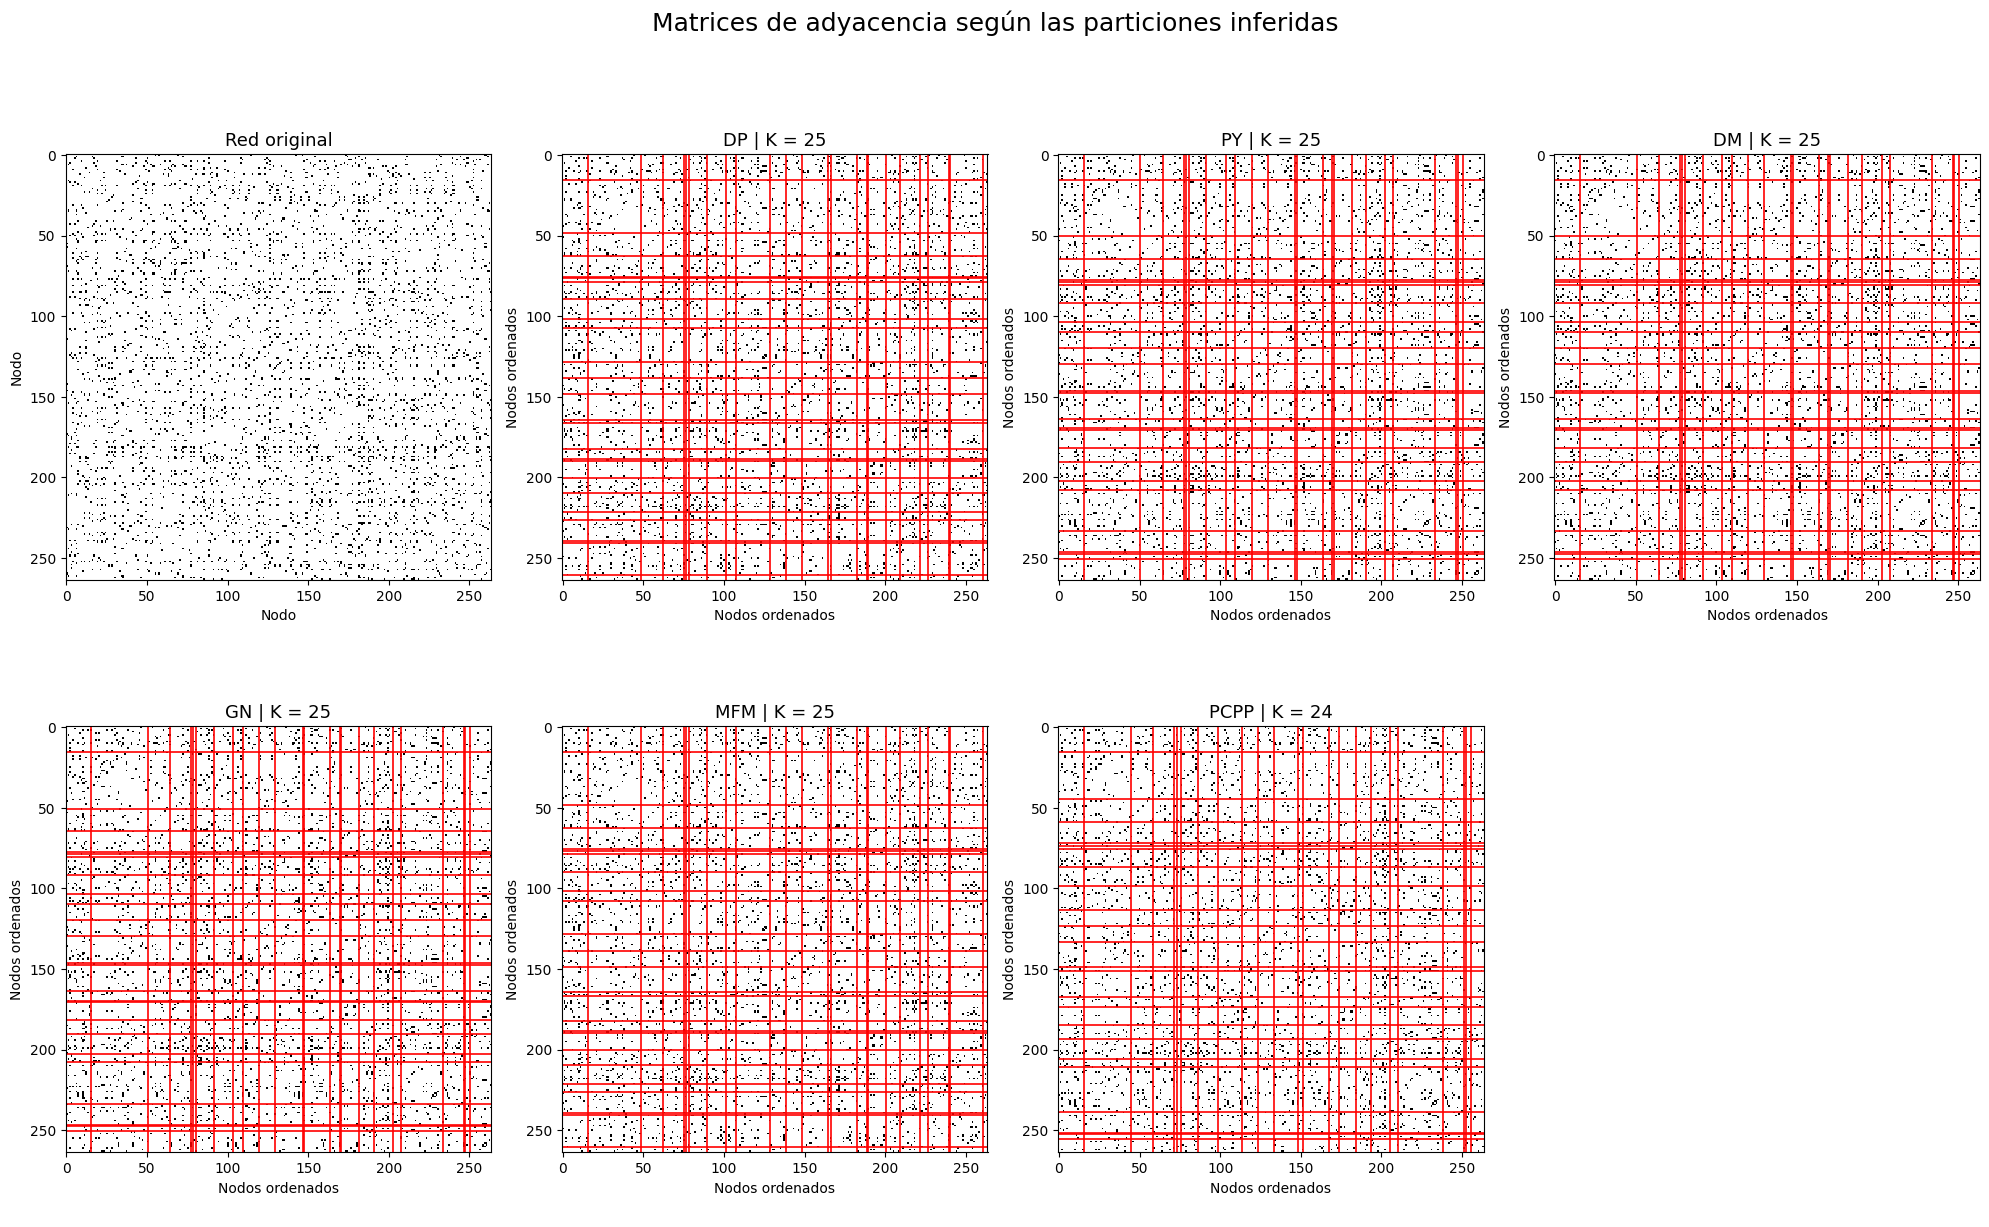

In [70]:
import numpy as np
import matplotlib.pyplot as plt

import pickle

# ============================================================
# 1. CARGAR RESULTADOS DESDE EL PICKLE
# ============================================================

filename = "SBM_colombian_politics_6_priors.pkl"

with open(filename, "rb") as f:
    all_results = pickle.load(f)

print("Resultados cargados correctamente.")
print("Total de inferencias:", len(all_results))

# ============================================================
# 2. SELECCIONAR INFERENCIAS EXITOSAS
# ============================================================

successful_results = {
    name: result
    for name, result in all_results.items()
    if result.get("status") == "success"
}

print("Inferencias exitosas:", len(successful_results))
print("Inferencias fallidas:", len(all_results) - len(successful_results))

# ============================================================
# 3. MOSTRAR PRIORS DISPONIBLES
# ============================================================

for name, result in successful_results.items():
    print(
        f"{name} | "
        f"Prior: {result['prior']} | "
        f"K final: {result['K_final']} | "
        f"Muestras: {result['saved_samples']}"
    )

# ============================================================
# 2. FUNCIÓN PARA ORDENAR LA MATRIZ SEGÚN UNA PARTICIÓN
# ============================================================

def reorder_adjacency(adjacency, labels):

    labels = np.asarray(labels)

    # Ordenar nodos por comunidad
    order = np.argsort(labels, kind="stable")

    # Reordenar filas y columnas
    A_sorted = adjacency[np.ix_(order, order)]

    # Identificar límites entre comunidades
    sorted_labels = labels[order]

    boundaries = np.where(
        sorted_labels[:-1] != sorted_labels[1:]
    )[0] + 1

    return A_sorted, order, boundaries


# ============================================================
# 3. FUNCIÓN DE VISUALIZACIÓN
# ============================================================

def plot_adjacency_partitions(
    adjacency,
    all_results,
    figsize=(20, 12)
):

    successful_results = {
        name: result
        for name, result in all_results.items()
        if result.get("status") == "success"
    }

    n_plots = len(successful_results) + 1

    ncols = 4
    nrows = int(np.ceil(n_plots / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=figsize
    )

    axes = np.array(axes).flatten()

    # --------------------------------------------------------
    # MATRIZ ORIGINAL
    # --------------------------------------------------------

    ax = axes[0]

    im = ax.imshow(
        adjacency,
        cmap="Greys",
        interpolation="none",
        vmin=0,
        vmax=1
    )

    ax.set_title("Red original", fontsize=13)

    ax.set_xlabel("Nodo")
    ax.set_ylabel("Nodo")

    # --------------------------------------------------------
    # MATRICES SEGÚN CADA PRIOR
    # --------------------------------------------------------

    for idx, (run_name, result) in enumerate(
        successful_results.items(),
        start=1
    ):

        labels = np.asarray(result["final_partition"])

        A_sorted, order, boundaries = reorder_adjacency(
            adjacency,
            labels
        )

        ax = axes[idx]

        ax.imshow(
            A_sorted,
            cmap="Greys",
            interpolation="none",
            vmin=0,
            vmax=1
        )

        K = len(np.unique(labels))

        prior_name = result.get("prior", run_name)

        ax.set_title(
            f"{prior_name} | K = {K}",
            fontsize=13
        )

        ax.set_xlabel("Nodos ordenados")
        ax.set_ylabel("Nodos ordenados")

        # ----------------------------------------------------
        # LÍNEAS DE SEPARACIÓN ENTRE COMUNIDADES
        # ----------------------------------------------------

        for boundary in boundaries:

            ax.axhline(
                boundary - 0.5,
                color="red",
                linewidth=1.2
            )

            ax.axvline(
                boundary - 0.5,
                color="red",
                linewidth=1.2
            )

    # --------------------------------------------------------
    # ELIMINAR EJES VACÍOS
    # --------------------------------------------------------

    for idx in range(n_plots, len(axes)):
        axes[idx].axis("off")

    # --------------------------------------------------------
    # AJUSTES GENERALES
    # --------------------------------------------------------

    fig.suptitle(
        "Matrices de adyacencia según las particiones inferidas",
        fontsize=18,
        y=1.02
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 4. EJECUTAR
# ============================================================

plot_adjacency_partitions(
    adjacency=adjacency,
    all_results=all_results,
    figsize=(20, 12)
)

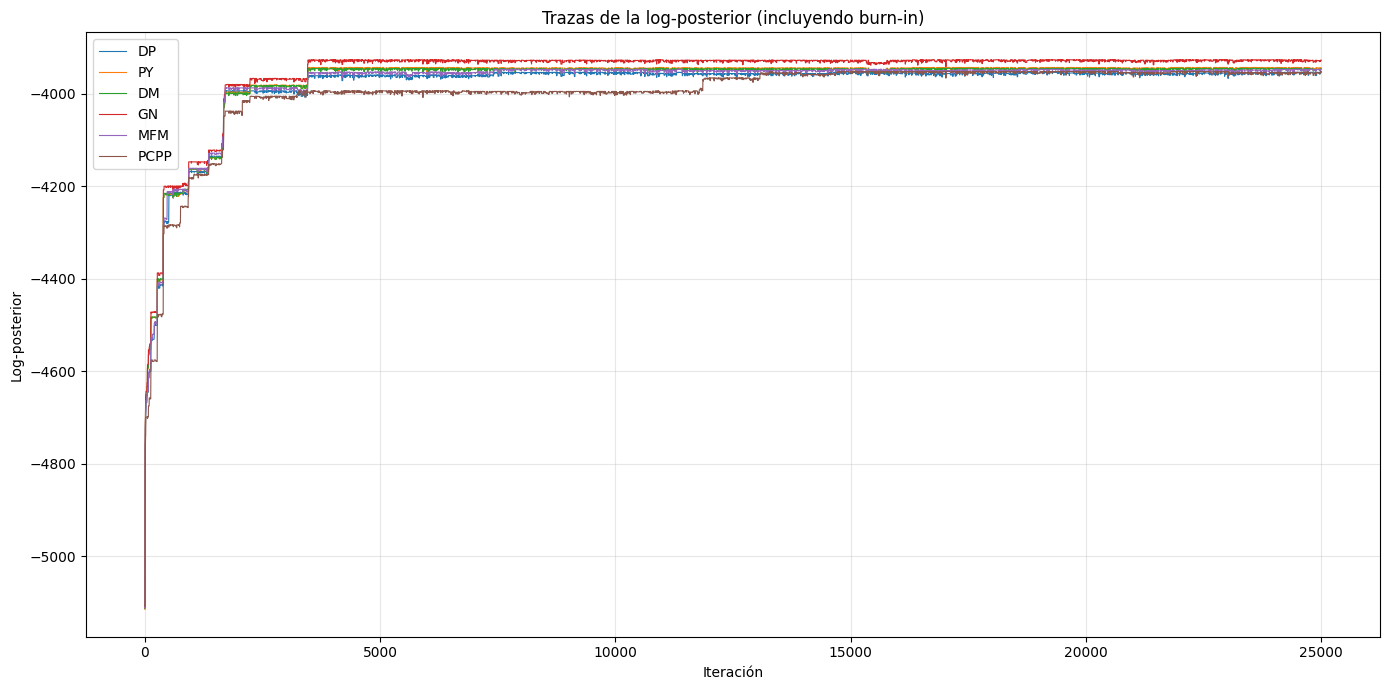

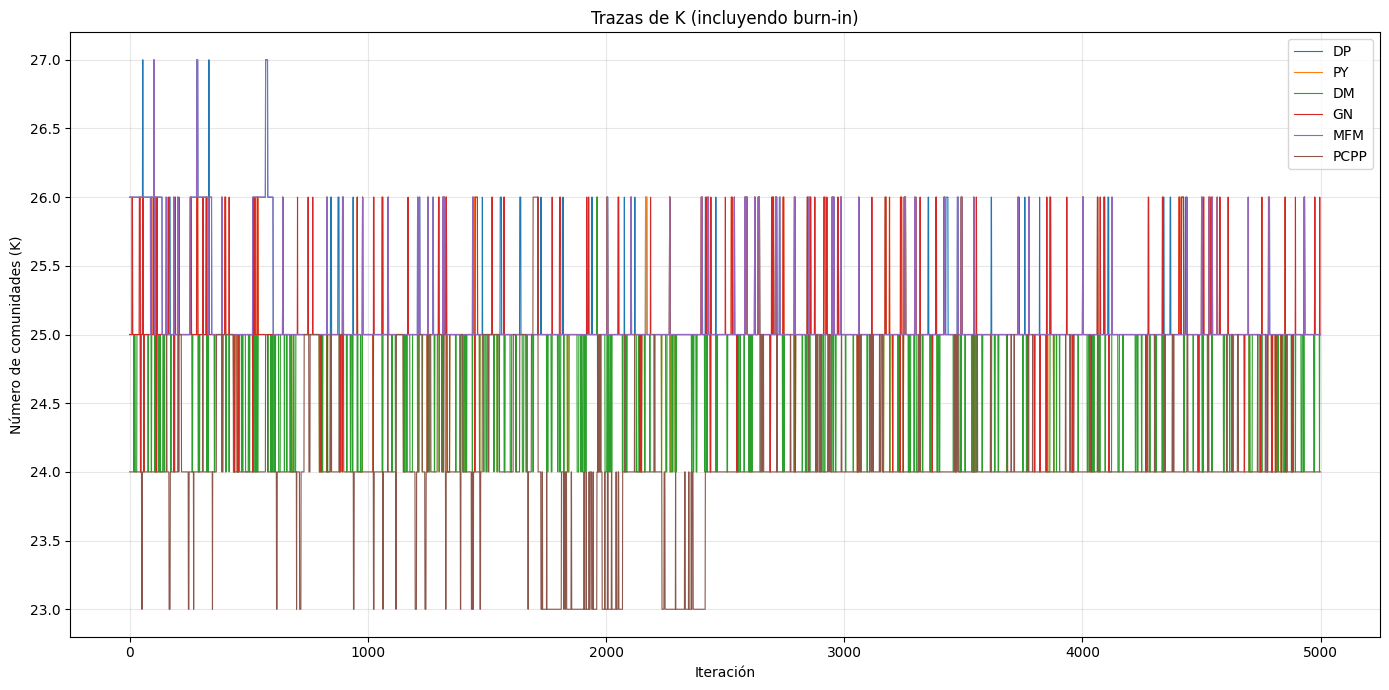

In [71]:
# ============================================================
# 6. LOG-POSTERIOR COMPLETA (INCLUYE BURN-IN)
# ============================================================

plt.figure(figsize=(14, 7))

for name, result in successful_results.items():

    log_posterior = np.asarray(result["log_posterior"])

    plt.plot(
        log_posterior,
        linewidth=0.8,
        label=result["prior"]
    )

plt.xlabel("Iteración")
plt.ylabel("Log-posterior")
plt.title("Trazas de la log-posterior (incluyendo burn-in)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 7. TRAZAS DE K (INCLUYE BURN-IN)
# ============================================================

plt.figure(figsize=(14, 7))

for name, result in successful_results.items():

    K_trace = np.asarray(result["K_trace"])

    plt.plot(
        K_trace,
        linewidth=0.8,
        label=result["prior"]
    )

plt.xlabel("Iteración")
plt.ylabel("Número de comunidades (K)")
plt.title("Trazas de K (incluyendo burn-in)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

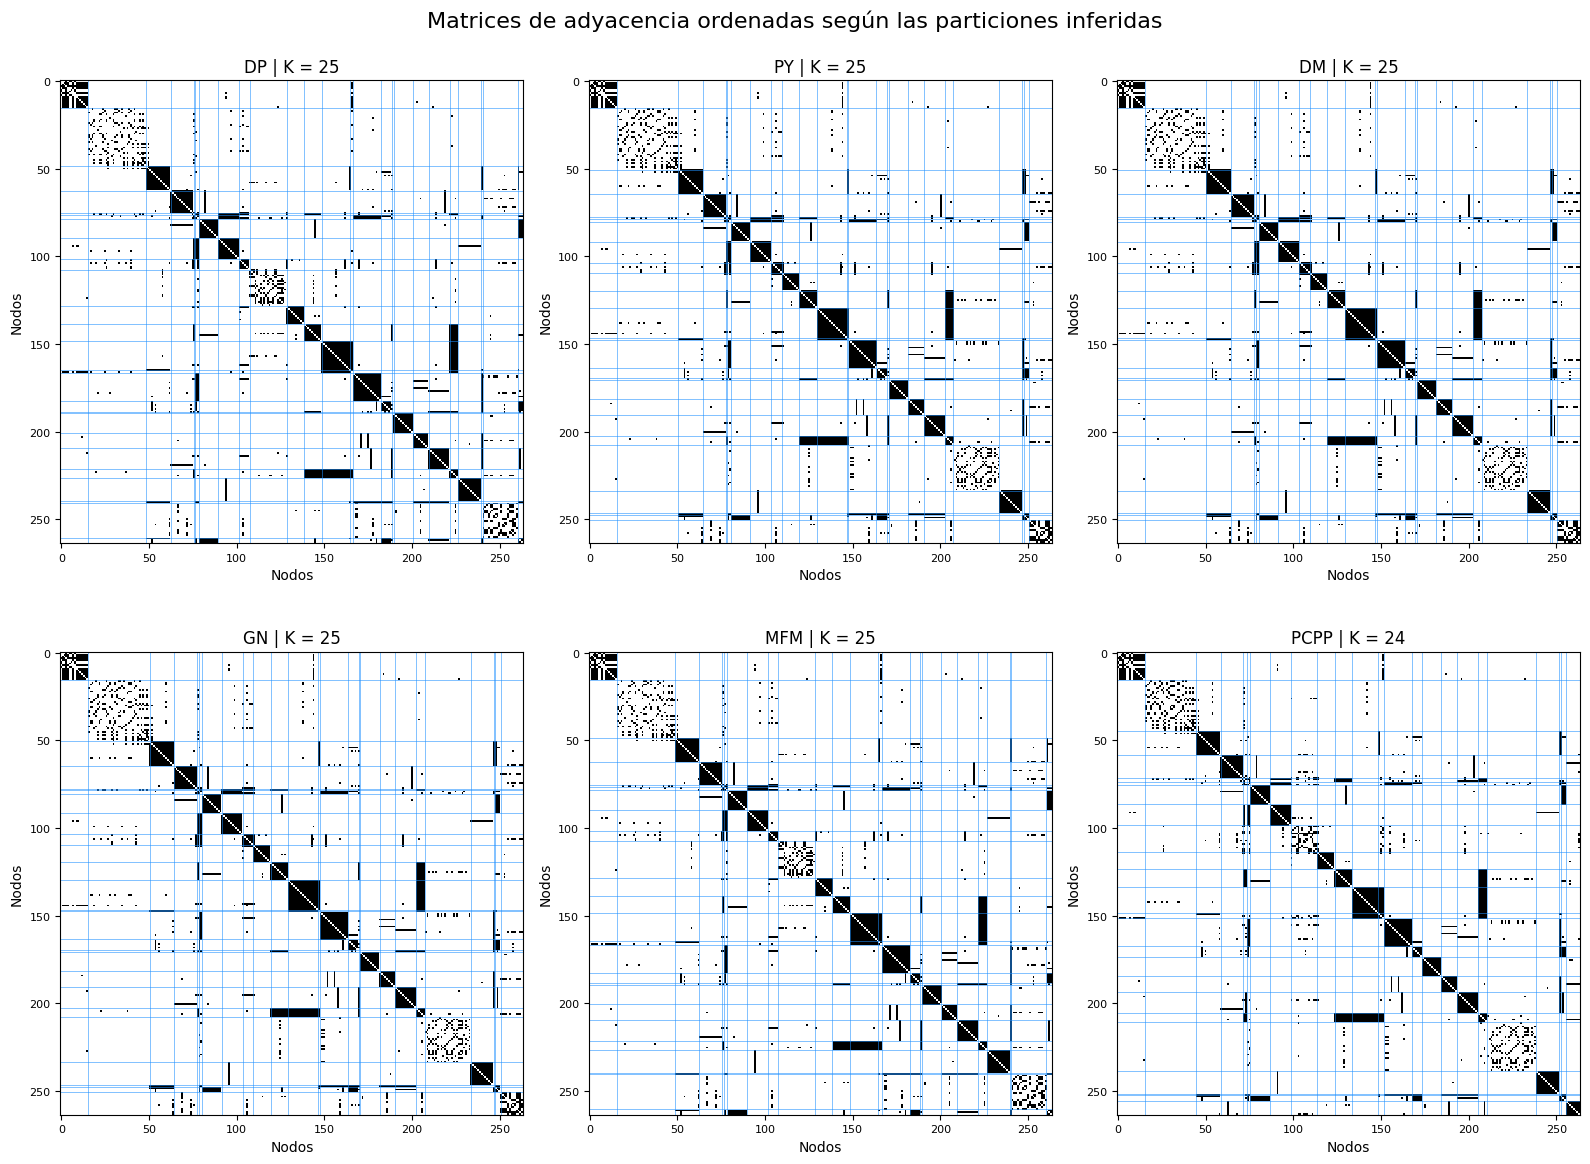

In [72]:
import numpy as np
import matplotlib.pyplot as plt

successful_results = {
    name: result
    for name, result in all_results.items()
    if result.get("status") == "success"
}


def reorder_adjacency(adjacency, labels):
    labels = np.asarray(labels)
    adjacency = np.asarray(adjacency)

    # Ordenar nodos según la etiqueta de comunidad
    order = np.argsort(labels, kind="stable")

    # Reordenar filas y columnas simultáneamente
    A_sorted = adjacency[np.ix_(order, order)]
    sorted_labels = labels[order]

    # Identificar límites entre comunidades
    boundaries = np.where(
        sorted_labels[:-1] != sorted_labels[1:]
    )[0] + 1

    return A_sorted, order, boundaries


# ------------------------------------------------------------
# MATRICES DE ADYACENCIA
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 12)
)

axes = axes.flatten()

for ax, (run_name, result) in zip(
    axes, successful_results.items()
):

    # Usar la matriz guardada para cada resultado
    A = result["adjacency"]
    labels = result["final_partition"]

    # Comprobar consistencia
    assert A.shape[0] == len(labels), (
        f"Inconsistencia en {run_name}: "
        f"matriz {A.shape} y etiquetas {len(labels)}"
    )

    A_sorted, order, boundaries = reorder_adjacency(
        A, labels
    )

    ax.imshow(
        A_sorted,
        cmap="Greys",
        interpolation="none",
        aspect="equal",
        vmin=0,
        vmax=1
    )

    # Separadores entre comunidades
    for boundary in boundaries:
        ax.axhline(
            boundary - 0.5,
            color="dodgerblue",
            linewidth=0.6,
            alpha=0.65
        )

        ax.axvline(
            boundary - 0.5,
            color="dodgerblue",
            linewidth=0.6,
            alpha=0.65
        )

    prior_name = result["prior"]
    K = len(np.unique(labels))

    ax.set_title(
        f"{prior_name} | K = {K}",
        fontsize=12
    )

    ax.set_xlabel("Nodos")
    ax.set_ylabel("Nodos")

    ax.tick_params(
        axis="both",
        labelsize=8
    )

fig.suptitle(
    "Matrices de adyacencia ordenadas según las particiones inferidas",
    fontsize=16
)

plt.tight_layout()
plt.show()

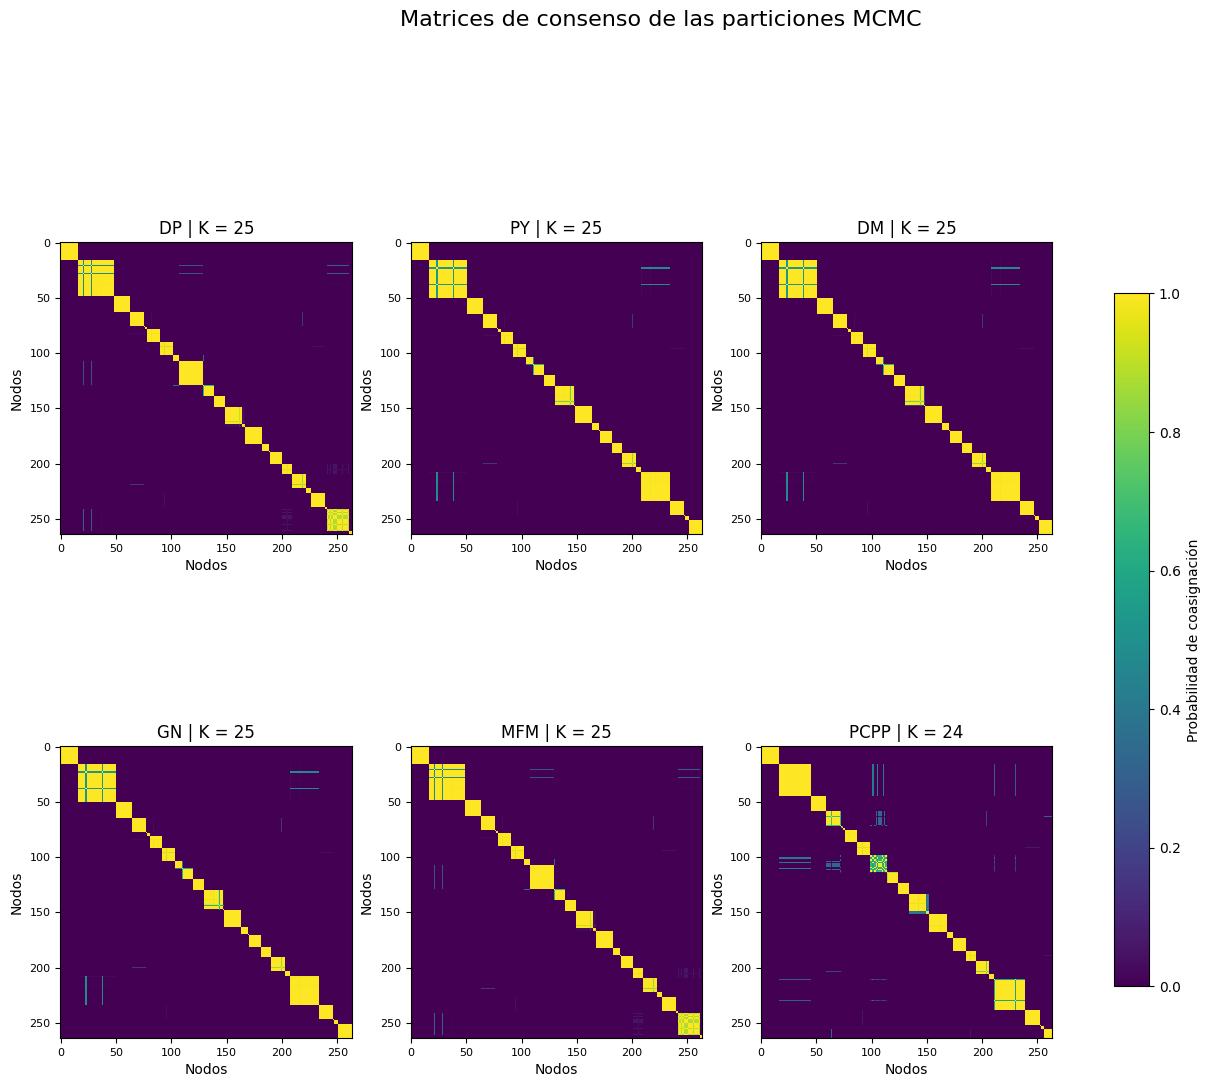

In [73]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# MATRICES DE CONSENSO
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 12)
)

axes = axes.flatten()

for ax, (run_name, result) in zip(
    axes, successful_results.items()
):

    samples = np.asarray(result["samples"])

    # samples: (n_muestras, n_nodos)
    n_samples, n_nodes = samples.shape

    # Matriz de consenso
    consensus = np.zeros(
        (n_nodes, n_nodes),
        dtype=float
    )

    for sample in samples:

        consensus += (
            sample[:, None] == sample[None, :]
        )

    consensus /= n_samples

    # Ordenar según la partición final
    labels = np.asarray(result["final_partition"])

    order = np.argsort(labels, kind="stable")

    consensus_sorted = consensus[np.ix_(order, order)]

    # Visualización
    im = ax.imshow(
        consensus_sorted,
        cmap="viridis",
        interpolation="none",
        aspect="equal",
        vmin=0,
        vmax=1
    )

    K = result["K_final"]

    ax.set_title(
        f"{result['prior']} | K = {K}",
        fontsize=12
    )

    ax.set_xlabel("Nodos")
    ax.set_ylabel("Nodos")

    ax.tick_params(labelsize=8)

fig.suptitle(
    "Matrices de consenso de las particiones MCMC",
    fontsize=16,
    y=1.02
)

# Barra de color común
fig.colorbar(
    im,
    ax=axes.tolist(),
    shrink=0.75,
    label="Probabilidad de coasignación"
)

#plt.tight_layout()
plt.show()

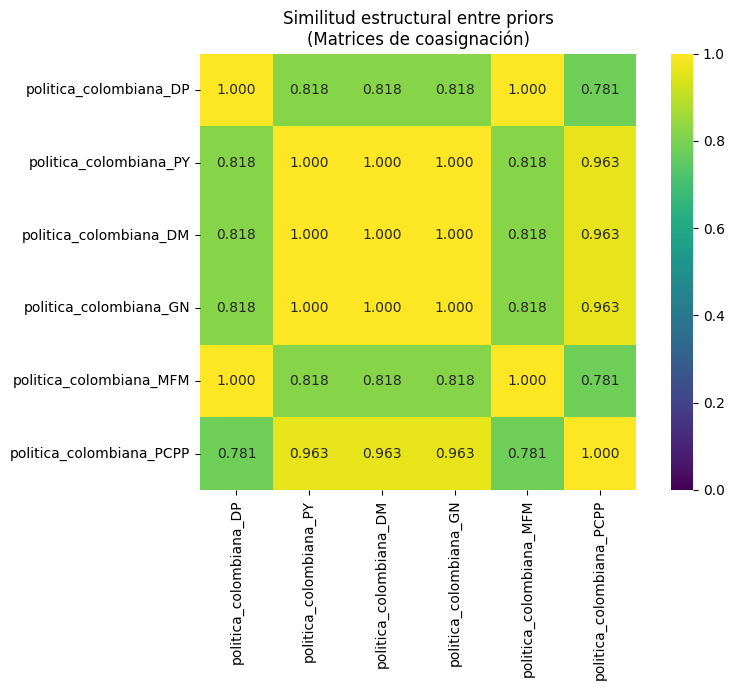

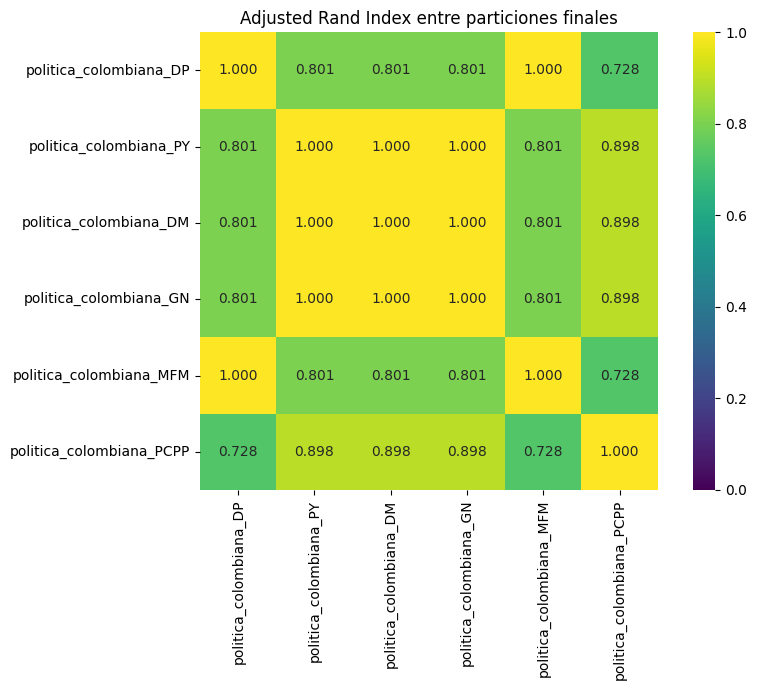

In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import adjusted_rand_score

# ============================================================
# 1. MATRICES DE COASIGNACIÓN
# ============================================================

def consensus_matrix(samples):

    samples = np.asarray(samples)
    S, n = samples.shape

    C = np.zeros((n, n), dtype=float)

    for z in samples:
        C += (z[:, None] == z[None, :])

    return C / S


consensus_matrices = {
    name: consensus_matrix(result["samples"])
    for name, result in successful_results.items()
}

prior_names = list(successful_results.keys())

# ============================================================
# 2. CORRELACIÓN ENTRE MATRICES DE CONSENSO
#    Excluimos la diagonal
# ============================================================

n_nodes = adjacency.shape[0]

upper_idx = np.triu_indices(n_nodes, k=1)

consensus_similarity = pd.DataFrame(
    index=prior_names,
    columns=prior_names,
    dtype=float
)

for p1 in prior_names:
    for p2 in prior_names:

        C1 = consensus_matrices[p1]
        C2 = consensus_matrices[p2]

        x = C1[upper_idx]
        y = C2[upper_idx]

        consensus_similarity.loc[p1, p2] = np.corrcoef(x, y)[0, 1]

# ============================================================
# 3. VISUALIZAR CORRELACIONES
# ============================================================

plt.figure(figsize=(9, 7))

sns.heatmap(
    consensus_similarity,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    vmin=0,
    vmax=1,
    square=True
)

plt.title("Similitud estructural entre priors\n(Matrices de coasignación)")
plt.tight_layout()
plt.show()

# ============================================================
# 4. ARI ENTRE PARTICIONES FINALES
# ============================================================

ARI_matrix = pd.DataFrame(
    index=prior_names,
    columns=prior_names,
    dtype=float
)

for p1 in prior_names:
    for p2 in prior_names:

        z1 = successful_results[p1]["final_partition"]
        z2 = successful_results[p2]["final_partition"]

        ARI_matrix.loc[p1, p2] = adjusted_rand_score(z1, z2)

plt.figure(figsize=(9, 7))

sns.heatmap(
    ARI_matrix,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    vmin=0,
    vmax=1,
    square=True
)

plt.title("Adjusted Rand Index entre particiones finales")
plt.tight_layout()
plt.show()

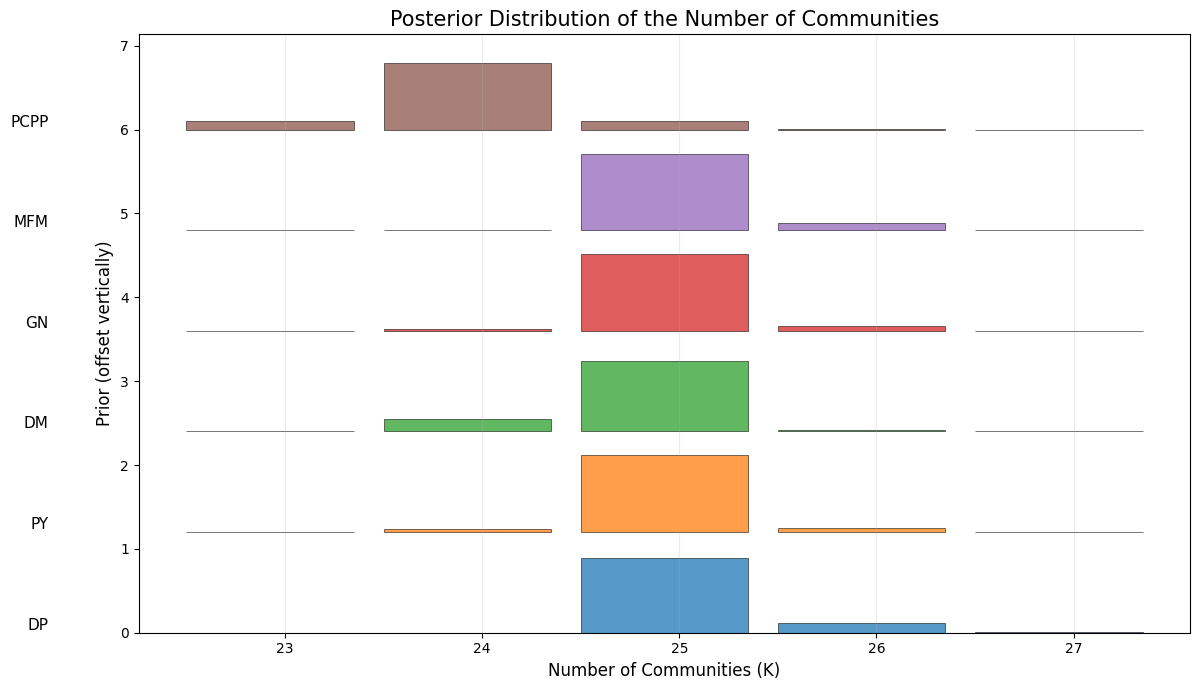

In [75]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. EXTRACT K FROM POSTERIOR SAMPLES
# ============================================================

K_samples = {}

for name, result in successful_results.items():

    samples = np.asarray(result["samples"])

    K_values = np.array([
        len(np.unique(z))
        for z in samples
    ])

    K_samples[result["prior"]] = K_values


# ============================================================
# 2. RIDGEPLOT WITH HISTOGRAMS
# ============================================================

prior_names = list(K_samples.keys())
n_priors = len(prior_names)

fig, ax = plt.subplots(figsize=(12, 7))

# Common bins for all priors
all_K = np.concatenate(list(K_samples.values()))

k_min = all_K.min()
k_max = all_K.max()

bins = np.arange(k_min - 0.5, k_max + 1.5, 1)

# Vertical separation between priors
spacing = 1.2

# ------------------------------------------------------------
# Plot histograms
# ------------------------------------------------------------

for i, prior_name in enumerate(prior_names):

    values = K_samples[prior_name]

    # Relative frequencies
    counts, _ = np.histogram(
        values,
        bins=bins,
        density=False
    )

    # Convert to probabilities
    probabilities = counts / counts.sum()

    # Vertical offset
    y_offset = i * spacing

    # Histogram bars
    ax.bar(
        bins[:-1],
        probabilities,
        width=0.85,
        bottom=y_offset,
        align="edge",
        alpha=0.75,
        edgecolor="black",
        linewidth=0.5
    )

    # Prior label
    ax.text(
        k_min - 1.2,
        y_offset,
        prior_name,
        ha="right",
        va="bottom",
        fontsize=11
    )

# ============================================================
# 3. FORMATTING
# ============================================================

ax.set_xlabel("Number of Communities (K)", fontsize=12)

ax.set_ylabel("Prior (offset vertically)", fontsize=12)

ax.set_title(
    "Posterior Distribution of the Number of Communities",
    fontsize=15
)

ax.set_xticks(np.arange(k_min, k_max + 1))

ax.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()
plt.show()